# NASA GIBS / MODIS: exploratory data analysis

This notebook explores six MODIS-derived Earth observation features served by NASA's
[Global Imagery Browse Services (GIBS)](https://nasa-gibs.github.io/gibs-api-docs/access-basics/):
vegetation, land temperature, sea temperature, ocean colour, aerosol and fires.

**GIBS serves pictures, not numbers**, so the first job is getting data values back out:

| Feature | How the values are recovered |
|---|---|
| Raster layers (NDVI, EVI, LST, SST, chlorophyll, AOD) | WMS `GetMap` PNG, then each pixel's RGB is looked up in the layer's published colormap XML |
| Fires (thermal anomalies) | WMTS Mapbox Vector Tiles, which carry one record per detection with FRP, brightness, confidence, satellite and time |

Downloads are cached in `data/`, so re-running is fast. Figures are saved to `figures/`.

## Key findings

1. **Fire follows the dry season around the globe.** African burning shifts from north of the equator in January (about 7,300 detections/day) to south of it in July and August (about 9,600/day).
2. **Canada's 2023 fire season stands out.** Boreal Canada stayed above 1,000 detections/day from May through September, then fell to 34/day in October.
3. **Fires are most frequent at middling greenness.** The rate peaks near NDVI 0.45–0.5 and drops off in both deserts and dense forest, a pattern a single correlation coefficient misses.
4. **Warm oceans tend to be low in chlorophyll.** Above about 20 °C most water sits near 0.1 mg/m³, while cooler water spans a much wider range.
5. **The El Niño record is clear.** Niño 3.4 anomalies peak at +2.8 °C in November 2015 and +2.0 °C in December 2023, with a low of −1.8 °C in December 2010.
6. **The recent drop in land temperature is mainly a satellite artifact, not cooling.** Terra's overpass has drifted earlier, and its anomaly falls far more than Aqua's. Long-term Terra LST shouldn't be trusted after about 2022 without correction.

In [1]:
import io, re, struct, warnings
import xml.etree.ElementTree as ET
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import HTML, display
from PIL import Image
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

DATA, FIG = Path("data"), Path("figures")
DATA.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

WMS = "https://gibs.earthdata.nasa.gov/wms/epsg4326/best/wms.cgi"
WMTS = "https://gibs.earthdata.nasa.gov/wmts/epsg4326/best"
COLORMAPS = "https://gibs.earthdata.nasa.gov/colormaps/v1.3"

session = requests.Session()
session.mount("https://", HTTPAdapter(
    pool_maxsize=8,
    max_retries=Retry(total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504]),
))

INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
OCEAN_BG, LAND_BG = "#fcfcfb", "#dcdbd5"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.edgecolor": "#c3c2b7",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "figure.facecolor": "white", "axes.facecolor": OCEAN_BG,
    "figure.dpi": 110, "savefig.dpi": 150,
})


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()


def show_plotly(fig, name):
    """Save a standalone page and embed the figure (no nbformat dependency)."""
    fig.write_html(FIG / f"{name}.html", include_plotlyjs="cdn")
    display(HTML(fig.to_html(full_html=False, include_plotlyjs="cdn")))

## 1. Getting values out of the API

`load_colormap` turns a layer's colormap XML into an RGB-to-value table and `decode` applies
it to an image. A bin's value is its midpoint. Open-ended end bins, such as LST "above 350 K",
use their inner bound, so **extremes are clipped at the end of the published scale**.

In [2]:
def load_colormap(name):
    """Return sorted RGB integer codes and their physical values for one colormap."""
    root = ET.fromstring(session.get(f"{COLORMAPS}/{name}.xml", timeout=60).content)
    rows = []
    for e in root.iter("ColorMapEntry"):
        if e.get("transparent") == "true" or e.get("nodata") == "true" or not e.get("value"):
            continue
        low, *high = re.findall(r"[-+]?(?:INF|[\d.]+)", e.get("value"))
        rgb = [int(v) for v in e.get("rgb").split(",")]
        rows.append(((rgb[0] << 16) | (rgb[1] << 8) | rgb[2], float(low), float(high[0]) if high else float(low)))
    table = pd.DataFrame(rows, columns=["code", "low", "high"])
    value = (table.low + table.high) / 2
    value.iloc[0] = table.high.iloc[0]    # inner bound of the open-ended low bin
    value.iloc[-1] = table.low.iloc[-1]   # inner bound of the open-ended high bin
    # A colour used by more than one bin is ambiguous, so average those bins.
    lut = value.groupby(table.code).mean()
    return lut.index.to_numpy(), lut.to_numpy(dtype="float32")


def get_image(layer, day, width, height, bbox="-90,-180,90,180", fmt="image/png"):
    """WMS 1.3.0 GetMap (EPSG:4326 axis order is lat,lon). Returns RGBA, or None when unavailable."""
    r = session.get(WMS, timeout=180, params=dict(
        version="1.3.0", service="WMS", request="GetMap", format=fmt, STYLES="", bbox=bbox,
        CRS="EPSG:4326", WIDTH=width, HEIGHT=height, TIME=day, layers=layer,
        **({"TRANSPARENT": "TRUE"} if fmt == "image/png" else {}),
    ))
    if not r.headers.get("content-type", "").startswith("image"):
        return None
    return np.array(Image.open(io.BytesIO(r.content)).convert("RGBA"))


def decode(rgba, codes, values):
    """Map RGBA pixels to physical values, with NaN where transparent."""
    out = np.full(rgba.shape[:2], np.nan, dtype="float32")
    px = rgba.astype("int64")
    code = (px[..., 0] << 16) | (px[..., 1] << 8) | px[..., 2]
    idx = np.clip(np.searchsorted(codes, code), 0, len(codes) - 1)
    hit = (codes[idx] == code) & (rgba[..., 3] > 0)
    out[hit] = values[idx[hit]]
    return out


def read_grid(feature, day, width, height):
    codes, values = COLORMAP_CACHE[feature["colormap"]]
    rgba = get_image(feature["layer"], day, width, height)
    if rgba is None:
        return np.full((height, width), np.nan, dtype="float32")
    return decode(rgba, codes, values) + feature.get("offset", 0)

In [3]:
MONTHS = pd.date_range("2023-01-01", periods=12, freq="MS")
SAMPLE_DAYS = pd.date_range("2023-01-01", "2023-12-31", freq="4D")   # every 4th day
MONTH_NAMES = MONTHS.strftime("%b").tolist()
W, H = 720, 360   # 0.5 degree global grid
lat = 90 - (np.arange(H) + 0.5) * 180 / H
lon = -180 + (np.arange(W) + 0.5) * 360 / W

FEATURES = {
    "ndvi": dict(layer="MODIS_Terra_L3_NDVI_Monthly", colormap="MODIS_L3_NDVI", cadence="monthly",
                 title="Vegetation: NDVI", units="index", vmin=0, vmax=0.9, cmap="YlGn"),
    "evi": dict(layer="MODIS_Terra_L3_EVI_Monthly", colormap="MODIS_L3_EVI", cadence="monthly",
                title="Vegetation: EVI", units="index", vmin=0, vmax=0.7, cmap="YlGn"),
    "lst": dict(layer="MODIS_Terra_L3_Land_Surface_Temp_Monthly_Day", colormap="MODIS_Land_Surface_Temp",
                cadence="monthly", offset=-273.15, title="Land surface temp, day", units="°C",
                vmin=-40, vmax=60, cmap="YlOrRd"),
    "sst": dict(layer="MODIS_Aqua_L3_SST_Thermal_4km_Night_Monthly", colormap="MODIS_Sea_Surface_Temperature",
                cadence="monthly", title="Sea surface temp, night", units="°C", vmin=0, vmax=32, cmap="RdPu",
                # GIBS has no Aqua monthly night grid for these 2023 months, so substitute the closest night product.
                fill={1: ("MODIS_Aqua_L3_SST_Thermal_4km_Night_8Day", ["2023-01-09", "2023-01-17", "2023-01-25"]),
                      6: ("MODIS_Terra_L3_SST_Thermal_4km_Night_Monthly", ["2023-06-01"])}),
    "chl": dict(layer="MODIS_Aqua_L2_Chlorophyll_A", colormap="MODIS_Chlorophyll", cadence="daily",
                title="Ocean colour: chlorophyll-a", units="mg/m³", vmin=0.03, vmax=10, cmap="BuGn", log=True),
    "aod": dict(layer="MODIS_Terra_AOD_Deep_Blue_Combined", colormap="MODIS_VIIRS_AOD", cadence="daily",
                title="Aerosol optical depth", units="unitless", vmin=0, vmax=1, cmap="YlOrBr"),
}
COLORMAP_CACHE = {f["colormap"]: load_colormap(f["colormap"]) for f in FEATURES.values()}


def fetch_cube(key):
    """12 monthly 0.5 degree grids. Daily layers are every-4th-day monthly median composites."""
    path = DATA / f"{key}_2023_0p5deg.npz"
    if path.exists():
        return np.load(path)["cube"]
    feature = FEATURES[key]
    days = MONTHS if feature["cadence"] == "monthly" else SAMPLE_DAYS
    with ThreadPoolExecutor(6) as pool:
        grids = list(pool.map(lambda d: read_grid(feature, d.strftime("%Y-%m-%d"), W, H), days))
    stack = np.stack(grids)
    if feature["cadence"] == "daily":
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            stack = np.stack([np.nanmedian(stack[days.month == m], axis=0) for m in range(1, 13)])
    for month, (layer, fill_days) in feature.get("fill", {}).items():
        filler = np.stack([read_grid(dict(feature, layer=layer), d, W, H) for d in fill_days])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            stack[month - 1] = np.nanmedian(filler, axis=0)
    np.savez_compressed(path, cube=stack.astype("float32"))
    return stack


cubes = {k: fetch_cube(k) for k in FEATURES}

### Fires: decoding vector tiles

At zoom 0 of the `1km` matrix set, two tiles (288° wide) cover the globe. Protobuf is simple
enough that a small dependency-free reader handles the Mapbox Vector Tile format. Coordinates
come straight from each record's `LATITUDE` and `LONGITUDE` attributes.

In [4]:
def _varint(b, i):
    shift = result = 0
    while True:
        c = b[i]
        i += 1
        result |= (c & 127) << shift
        shift += 7
        if c < 128:
            return result, i


def _fields(b):
    i = 0
    while i < len(b):
        key, i = _varint(b, i)
        number, wire = key >> 3, key & 7
        if wire == 0:
            v, i = _varint(b, i)
        elif wire == 1:
            v, i = b[i:i + 8], i + 8
        elif wire == 2:
            size, i = _varint(b, i)
            v, i = b[i:i + size], i + size
        elif wire == 5:
            v, i = b[i:i + 4], i + 4
        else:
            raise ValueError(f"unsupported wire type {wire}")
        yield number, v


def _value(b):
    for number, v in _fields(b):
        if number == 1:
            return v.decode()
        if number == 2:
            return struct.unpack("<f", v)[0]
        if number == 3:
            return struct.unpack("<d", v)[0]
        if number in (4, 5):
            return v
        if number == 6:
            return (v >> 1) ^ -(v & 1)
        if number == 7:
            return bool(v)


def parse_mvt(buf):
    """Return the feature attributes in a vector tile as a list of dicts."""
    rows = []
    for number, layer in _fields(buf):
        if number != 3:
            continue
        keys, values, features = [], [], []
        for n, v in _fields(layer):
            if n == 2:
                features.append(v)
            elif n == 3:
                keys.append(v.decode())
            elif n == 4:
                values.append(_value(v))
        for feat in features:
            for n, v in _fields(feat):
                if n == 2:
                    tags, i = [], 0
                    while i < len(v):
                        t, i = _varint(v, i)
                        tags.append(t)
                    rows.append({keys[tags[j]]: values[tags[j + 1]] for j in range(0, len(tags), 2)})
    return rows


FIRE_LAYER = "MODIS_Combined_Thermal_Anomalies_All"
FIRE_COLS = ["LATITUDE", "LONGITUDE", "BRIGHTNESS", "BRIGHT_T31", "FRP", "CONFIDENCE",
             "SATELLITE", "DAYNIGHT", "ACQ_DATE", "ACQ_TIME"]
FIRE_KEY = ["LATITUDE", "LONGITUDE", "ACQ_TIME", "SATELLITE"]


def fire_tile(day, zoom, row, col):
    r = session.get(f"{WMTS}/{FIRE_LAYER}/default/{day}/1km/{zoom}/{row}/{col}.mvt", timeout=180)
    if r.status_code != 200 or not r.content:
        return []
    return parse_mvt(r.content)


def fire_day(day):
    frame = pd.DataFrame(fire_tile(day, 0, 0, 0) + fire_tile(day, 0, 0, 1))
    if frame.empty:
        return frame
    return frame[FIRE_COLS].drop_duplicates(FIRE_KEY)


def fetch_fires():
    path = DATA / "fires_2023.csv.gz"
    if path.exists():
        return pd.read_csv(path, parse_dates=["ACQ_DATE"])
    with ThreadPoolExecutor(6) as pool:
        frames = list(pool.map(lambda d: fire_day(d.strftime("%Y-%m-%d")), SAMPLE_DAYS))
    fires = pd.concat(frames, ignore_index=True)
    fires.to_csv(path, index=False)
    fires["ACQ_DATE"] = pd.to_datetime(fires["ACQ_DATE"])
    return fires


fires = fetch_fires().rename(columns=str.lower)
fires = fires[fires.acq_date.dt.year == 2023].copy()
# Keep nominal and high confidence detections for gridded analysis (FIRMS: low is below 30).
good_fires = fires[fires.confidence >= 30]
days_per_month = pd.Series(SAMPLE_DAYS.month).value_counts().sort_index()

fire_rate = np.zeros((12, H, W), dtype="float32")   # detections per sampled day per cell
for m, group in good_fires.groupby(good_fires.acq_date.dt.month):
    counts, _, _ = np.histogram2d(group.latitude, group.longitude, bins=[H, W], range=[[-90, 90], [-180, 180]])
    fire_rate[m - 1] = counts[::-1] / days_per_month[m]

### Validating the pipeline

Three checks before trusting any chart: do colours round-trip, do low-zoom fire tiles contain
everything, and are the values physically plausible?

In [5]:
def check_colormap(key):
    feature = FEATURES[key]
    day = "2023-07-01" if feature["cadence"] == "monthly" else "2023-07-15"
    rgba = get_image(feature["layer"], day, W, H)
    grid = decode(rgba, *COLORMAP_CACHE[feature["colormap"]])
    opaque = rgba[..., 3] > 0
    return np.isfinite(grid[opaque]).mean()


def summary(key):
    q = np.nanpercentile(cubes[key], [1, 50, 99])
    return dict(feature=FEATURES[key]["title"], layer=FEATURES[key]["layer"], units=FEATURES[key]["units"],
                pixels_decoded=f"{check_colormap(key):.2%}",
                cell_months_with_data=f"{np.isfinite(cubes[key]).mean():.1%}",
                p1=round(float(q[0]), 2), median=round(float(q[1]), 2), p99=round(float(q[2]), 2))


display(pd.DataFrame([summary(k) for k in FEATURES]).set_index("feature"))

# Are the two zoom-0 tiles complete? Compare them with all six zoom-1 tiles for the same day.
z0 = pd.DataFrame(fire_tile("2023-07-15", 0, 0, 0) + fire_tile("2023-07-15", 0, 0, 1)).drop_duplicates(FIRE_KEY)
z1 = pd.DataFrame([x for r in range(2) for c in range(3) for x in fire_tile("2023-07-15", 1, r, c)]).drop_duplicates(FIRE_KEY)
print(f"Fire detections on 2023-07-15: zoom 0 = {len(z0):,}, zoom 1 = {len(z1):,}")
print(f"Fire table: {len(fires):,} detections on {fires.acq_date.nunique()} sampled days, "
      f"{len(good_fires):,} at confidence >= 30")
print("Date range:", fires.acq_date.min().date(), "to", fires.acq_date.max().date())
print("Share of each 2023 SST month with data:", np.isfinite(cubes["sst"]).mean(axis=(1, 2)).round(2).tolist())

,layer,units,pixels_decoded,cell_months_with_data,p1,median,p99
feature,,,,,,,
Vegetation: NDVI,MODIS_Terra_L3_NDVI_Monthly,index,100.00%,20.3%,0.01,0.43,0.90
Vegetation: EVI,MODIS_Terra_L3_EVI_Monthly,index,100.00%,20.3%,0.01,0.22,0.66
"Land surface temp, day",MODIS_Terra_L3_Land_Surface_Temp_Monthly_Day,°C,100.00%,34.0%,-66.25,5.75,48.95
"Sea surface temp, night",MODIS_Aqua_L3_SST_Thermal_4km_Night_Monthly,°C,100.00%,53.8%,0.00,20.77,30.38
Ocean colour: chlorophyll-a,MODIS_Aqua_L2_Chlorophyll_A,mg/m³,100.00%,51.2%,0.01,0.11,4.74
Aerosol optical depth,MODIS_Terra_AOD_Deep_Blue_Combined,unitless,100.00%,52.5%,0.01,0.12,0.79


Fire detections on 2023-07-15: zoom 0 = 18,406, zoom 1 = 18,406
Fire table: 1,145,248 detections on 92 sampled days, 1,084,876 at confidence >= 30
Date range: 2023-01-01 to 2023-12-31
Share of each 2023 SST month with data: [0.54, 0.55, 0.55, 0.54, 0.53, 0.53, 0.52, 0.54, 0.56, 0.55, 0.53, 0.53]


## 2. Where is each feature, and how does it shift with the seasons?

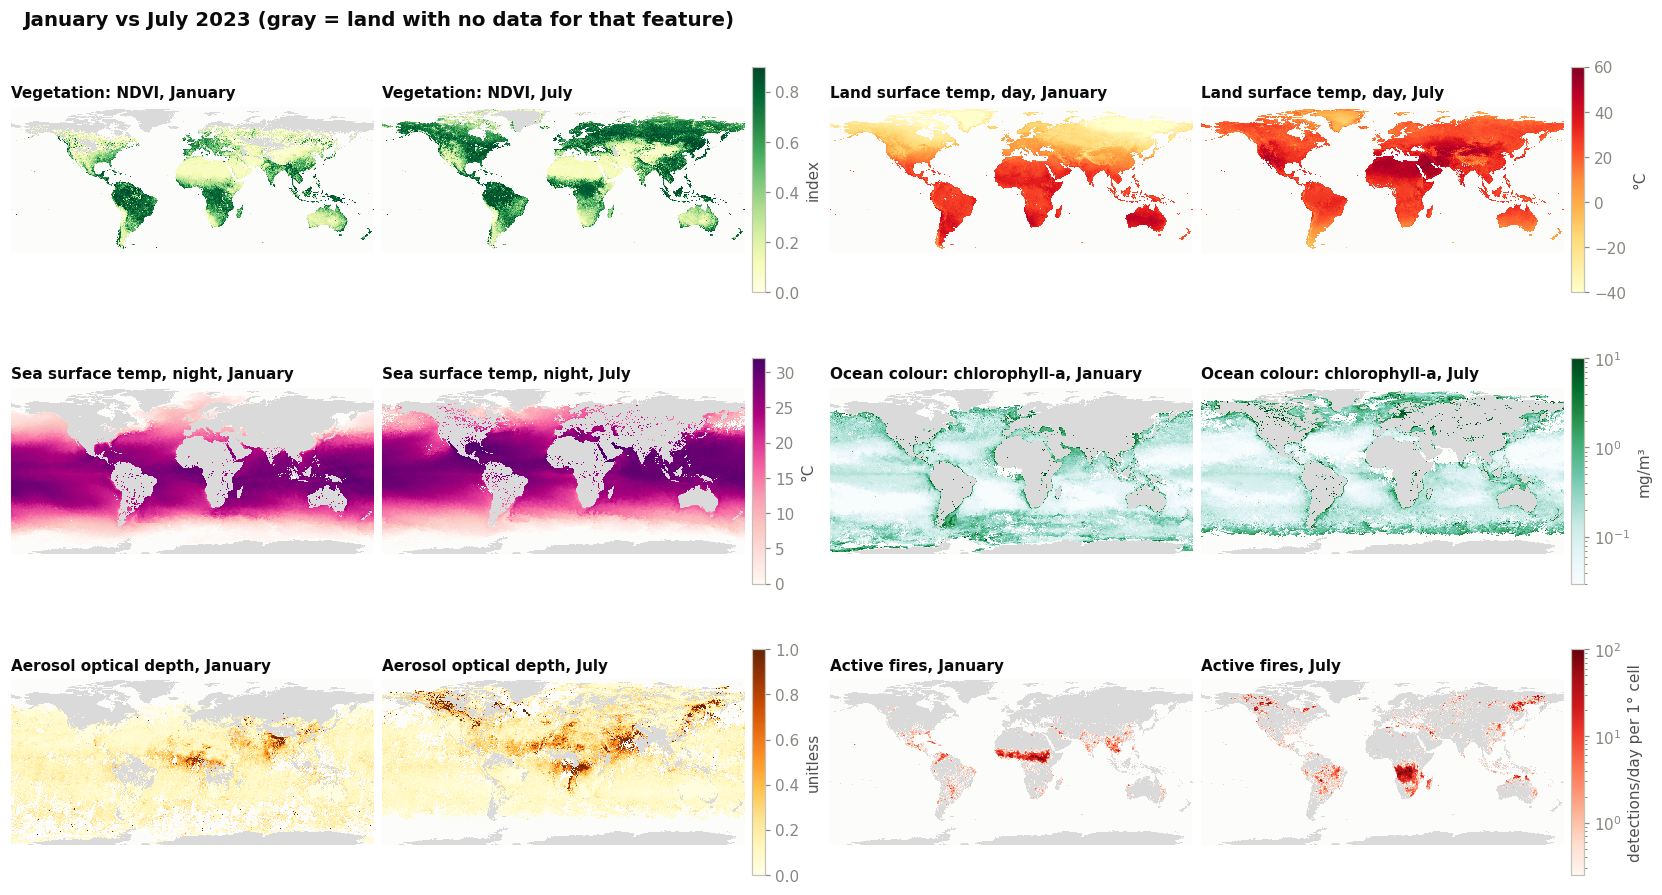

In [6]:
def coarsen(a, f, how="mean"):
    """Aggregate the last two axes by factor f, ignoring NaN."""
    new_shape = a.shape[:-2] + (a.shape[-2] // f, f, a.shape[-1] // f, f)
    r = a.reshape(new_shape)
    if how == "sum":
        return np.nansum(r, axis=(-3, -1))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        if how == "geomean":
            return np.exp(np.nanmean(np.log(np.where(r > 0, r, np.nan)), axis=(-3, -1)))
        return np.nanmean(r, axis=(-3, -1))


land = np.isfinite(cubes["ndvi"]).any(axis=0) | np.isfinite(cubes["lst"]).any(axis=0)
EXTENT = [-180, 180, -90, 90]
PANELS = ["ndvi", "lst", "sst", "chl", "aod", "fire"]
fire_title, fire_units = "Active fires", "detections/day per 1° cell"


def draw_map(ax, key, month):
    ax.imshow(np.where(land, 1.0, np.nan), extent=EXTENT, cmap="gray", vmin=0, vmax=1.17, interpolation="nearest")
    if key == "fire":
        z = coarsen(fire_rate[month], 2, "sum")
        z = np.where(z > 0, z, np.nan)
        im = ax.imshow(z, extent=EXTENT, cmap="Reds", norm=LogNorm(0.25, 100), interpolation="nearest")
    else:
        f = FEATURES[key]
        norm = LogNorm(f["vmin"], f["vmax"]) if f.get("log") else plt.Normalize(f["vmin"], f["vmax"])
        im = ax.imshow(cubes[key][month], extent=EXTENT, cmap=f["cmap"], norm=norm, interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_ylim(-60, 85) if key in ("ndvi", "lst") else ax.set_ylim(-80, 85)
    for s in ax.spines.values():
        s.set_visible(False)
    return im


fig, axes = plt.subplots(3, 4, figsize=(15, 8.2), layout="constrained")
for i, key in enumerate(PANELS):
    pair = axes[i // 2, (i % 2) * 2:(i % 2) * 2 + 2]
    for ax, month, name in zip(pair, (0, 6), ("January", "July")):
        im = draw_map(ax, key, month)
        title = fire_title if key == "fire" else FEATURES[key]["title"]
        ax.set_title(f"{title}, {name}", loc="left", fontsize=10)
    units = fire_units if key == "fire" else FEATURES[key]["units"]
    fig.colorbar(im, ax=list(pair), shrink=0.8, label=units, pad=0.01, aspect=18)
fig.suptitle("January vs July 2023 (gray = land with no data for that feature)", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
save(fig, "01_january_vs_july")

**What stands out**

- **Vegetation and temperature:** the northern forests swing hardest. Boreal Canada goes from NDVI 0.12 and −20 °C in January to 0.64 and +22 °C in July, while the Amazon stays near 0.8 and 27 °C.
- **Fire:** Africa's burning belt moves across the equator between January and July.
- **Aerosol:** high values sit near the burning regions, including West Africa in January and central Africa in July. Smoke from Canada is also visible in July.
- **Ocean colour:** chlorophyll is lowest in the subtropical gyres and highest in coastal and high-latitude waters.

January SST comes from an Aqua 8-day product and June SST from Terra, because GIBS has no Aqua monthly night grid for those months.

### Interactive: all features through the year

Drag the slider or press Play to step through 2023. Hover for values. Grids are aggregated to
3° to keep the page light. If this figure is blank, trust the notebook (`jupyter trust eda.ipynb`)
or open `figures/02_monthly_explorer.html` directly.

In [7]:
FACTOR = 6
lat3 = coarsen(lat[None, :, None].repeat(W, 2), FACTOR)[0, :, 0]
lon3 = coarsen(lon[None, None, :].repeat(H, 1), FACTOR)[0, 0, :]


def panel_frame(key, month):
    if key == "fire":
        z = coarsen(fire_rate[month], FACTOR, "sum")
        return np.log10(np.where(z > 0, z, np.nan)).astype("float32")
    if FEATURES[key].get("log"):
        return np.log10(coarsen(cubes[key][month], FACTOR, "geomean")).astype("float32")
    return coarsen(cubes[key][month], FACTOR).astype("float32")


COLORSCALES = dict(ndvi="YlGn", lst="YlOrRd", sst="RdPu", chl="BuGn", aod="YlOrBr", fire="Reds")
LIMITS = dict(ndvi=(0, 0.9), lst=(-40, 60), sst=(0, 32), chl=(np.log10(0.03), 1), aod=(0, 1), fire=(-0.5, 2.5))
LABELS = dict(ndvi="NDVI", lst="LST °C", sst="SST °C", chl="log₁₀ chl-a (mg/m³)", aod="AOD", fire="log₁₀ fires/day")
PANEL_TITLES = {k: (fire_title if k == "fire" else FEATURES[k]["title"]) for k in PANELS}
XS = [0.285, 0.645, 1.005]
YS = [0.79, 0.21]


def heatmap(key, month, i):
    return go.Heatmap(
        z=panel_frame(key, month), x=lon3, y=lat3, colorscale=COLORSCALES[key],
        zmin=LIMITS[key][0], zmax=LIMITS[key][1], hoverongaps=False, name=PANEL_TITLES[key],
        hovertemplate="lat %{y:.1f}°, lon %{x:.1f}°<br>" + LABELS[key] + " = %{z:.2f}<extra></extra>",
        colorbar=dict(x=XS[i % 3], y=YS[i // 3], len=0.38, thickness=10, title=dict(text=LABELS[key], side="right")),
    )


explorer = make_subplots(rows=2, cols=3, subplot_titles=[PANEL_TITLES[k] for k in PANELS],
                         horizontal_spacing=0.07, vertical_spacing=0.11)
for i, key in enumerate(PANELS):
    explorer.add_trace(heatmap(key, 0, i), row=i // 3 + 1, col=i % 3 + 1)
explorer.frames = [
    go.Frame(name=name, data=[heatmap(k, m, i) for i, k in enumerate(PANELS)], traces=list(range(6)))
    for m, name in enumerate(MONTH_NAMES)
]
play = dict(frame=dict(duration=800, redraw=True), transition=dict(duration=0), fromcurrent=True)
explorer.update_layout(
    height=640, width=1180, plot_bgcolor="#eeede8", paper_bgcolor="white", margin=dict(t=60, b=90, l=30, r=40),
    title=dict(text="MODIS features by month, 2023", x=0.01),
    font=dict(family="system-ui, Segoe UI, sans-serif", color=INK2),
    updatemenus=[dict(type="buttons", direction="left", x=0.0, y=-0.1, xanchor="left", yanchor="top",
                      buttons=[dict(label="Play", method="animate", args=[None, play]),
                               dict(label="Pause", method="animate",
                                    args=[[None], dict(mode="immediate", frame=dict(duration=0, redraw=False))])])],
    sliders=[dict(active=0, x=0.14, len=0.86, y=-0.05, currentvalue=dict(prefix="Month: "),
                  steps=[dict(label=n, method="animate",
                              args=[[n], dict(mode="immediate", frame=dict(duration=0, redraw=True))])
                         for n in MONTH_NAMES])],
)
explorer.update_xaxes(showticklabels=False, showgrid=False, zeroline=False, range=[-180, 180])
explorer.update_yaxes(showticklabels=False, showgrid=False, zeroline=False, range=[-80, 85])
show_plotly(explorer, "02_monthly_explorer")

## 3. Seasonal structure by latitude

Each panel below is a latitude-by-month summary, so a global seasonal pattern reads as a
single picture without any maps.

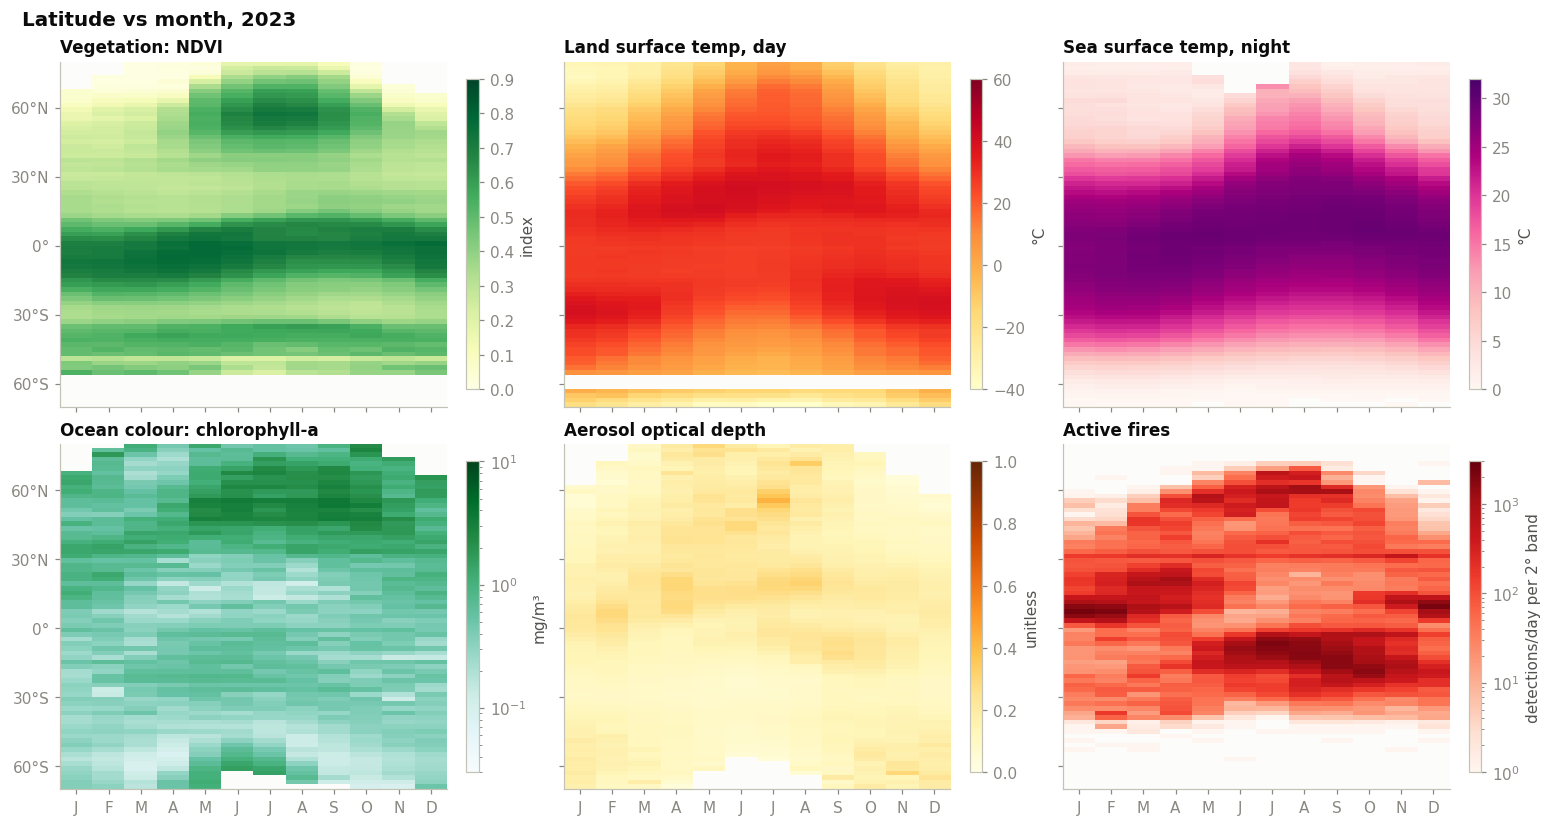

In [8]:
def zonal(key):
    """Zonal summary by 2 degree latitude band and month."""
    if key == "fire":
        return coarsen(fire_rate, 4, "sum").sum(axis=-1)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        how = "geomean" if FEATURES[key].get("log") else "mean"
        return np.nanmean(coarsen(cubes[key], 4, how), axis=-1)


fig, axes = plt.subplots(2, 3, figsize=(14, 7.4), layout="constrained", sharex=True, sharey=True)
for ax, key in zip(axes.flat, PANELS):
    z = zonal(key).T
    if key == "fire":
        z = np.where(z > 0, z, np.nan)
        im = ax.imshow(z, aspect="auto", extent=[-0.5, 11.5, -90, 90], cmap="Reds", norm=LogNorm(1, 3000), interpolation="nearest")
        label, title = "detections/day per 2° band", fire_title
    else:
        f = FEATURES[key]
        norm = LogNorm(f["vmin"], f["vmax"]) if f.get("log") else plt.Normalize(f["vmin"], f["vmax"])
        im = ax.imshow(z, aspect="auto", extent=[-0.5, 11.5, -90, 90], cmap=f["cmap"], norm=norm, interpolation="nearest")
        label, title = f["units"], f["title"]
    fig.colorbar(im, ax=ax, label=label, shrink=0.9, aspect=25)
    ax.set_title(title, loc="left")
    ax.set_xticks(range(12), [n[0] for n in MONTH_NAMES])
    ax.set_yticks(range(-60, 90, 30), [f"{abs(v)}°{'S' if v < 0 else 'N' if v > 0 else ''}" for v in range(-60, 90, 30)])
    ax.set_ylim(-70, 80)
    ax.grid(False)
fig.suptitle("Latitude vs month, 2023", x=0.01, ha="left", fontweight="bold", fontsize=13)
save(fig, "03_latitude_month")

**What stands out**

- **Fire has two bands.** One sits near 10°N in December to February and the other near 10–15°S from June to October. A third appears at high northern latitudes in summer.
- **NDVI and LST** show the expected summer peak at high northern latitudes, and little seasonal change near the equator.
- **Missing areas matter.** Blank high-latitude cells are mostly polar night, snow or ice. The chlorophyll values at 60°S in May to July rest on few retrievals at the edge of coverage, so they may not be a real bloom.

## 4. Seasonal cycles in eight contrasting regions

Land boxes are used for land features, ocean boxes for ocean features, and all eight for
aerosol. Each region keeps the same colour in every panel. Means are weighted by the cosine of
latitude, chlorophyll uses a geometric mean, and fires are totals.

,lat south,lat north,lon west,lon east,type
Amazon,-10,0,-70,-55,land
Congo Basin,-5,5,15,30,land
Sahara,18,30,-10,25,land
Boreal Canada,50,65,-125,-70,land
California,32,42,-124,-114,land
North Atlantic,45,60,-40,-20,ocean
Niño 3.4 (Pacific),-5,5,-170,-120,ocean
Arabian Sea,8,22,55,70,ocean


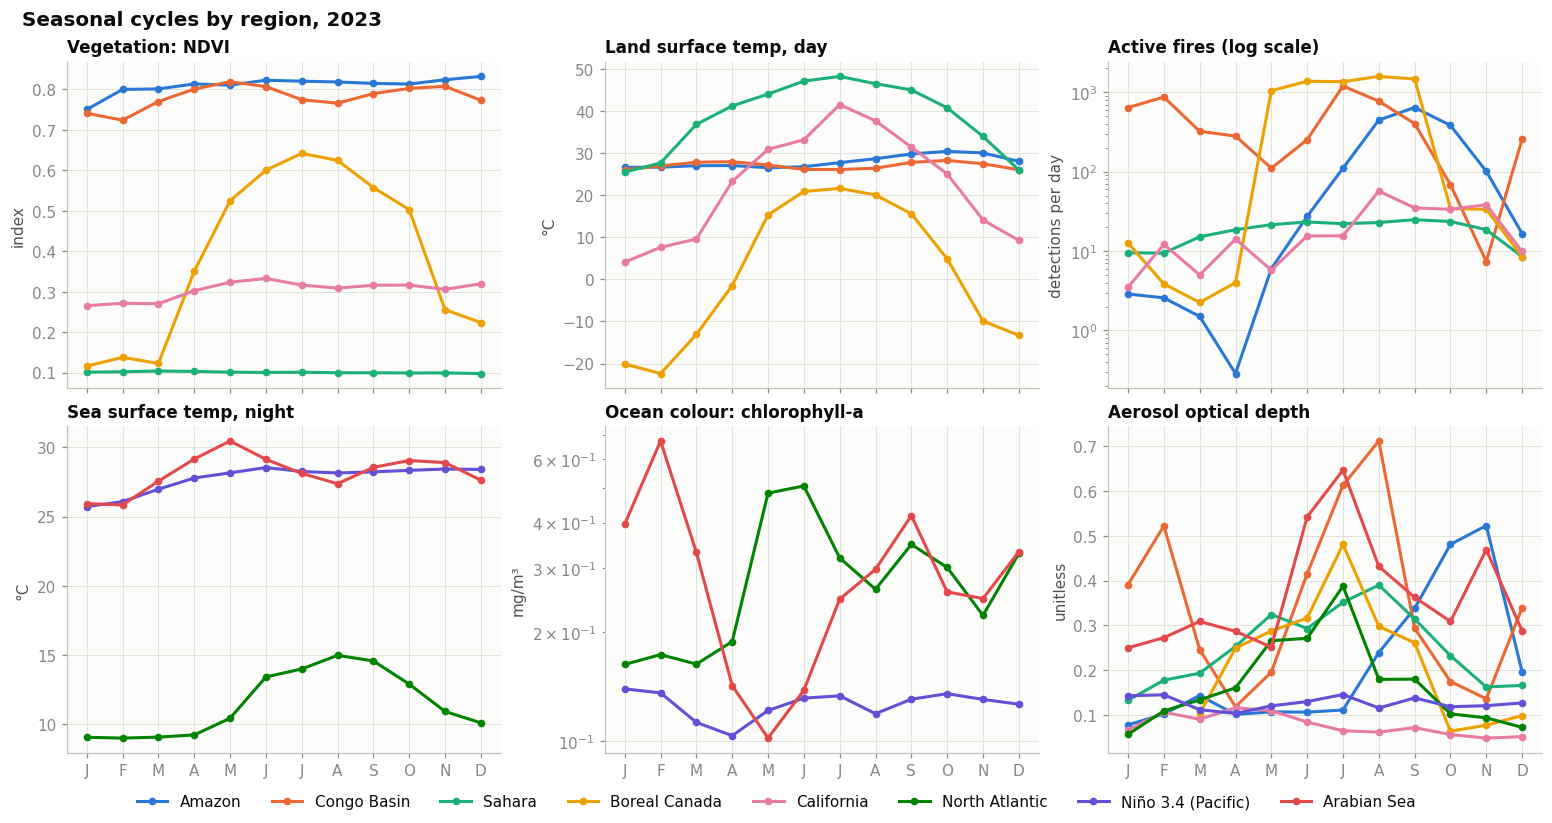

,Vegetation: NDVI,"Land surface temp, day","Sea surface temp, night",Ocean colour: chlorophyll-a,Aerosol optical depth,Active fires
"[Jan, Jul]",,,,,,
Amazon,"[0.75, 0.82]","[26.6, 27.74]",,,"[0.08, 0.11]","[2.88, 110.71]"
Congo Basin,"[0.74, 0.77]","[26.02, 26.1]",,,"[0.39, 0.61]","[642.5, 1202.0]"
Sahara,"[0.1, 0.1]","[25.51, 48.23]",,,"[0.13, 0.35]","[9.5, 22.14]"
Boreal Canada,"[0.12, 0.64]","[-20.1, 21.61]",,,"[nan, 0.48]","[12.62, 1362.29]"
California,"[0.27, 0.32]","[4.1, 41.53]",,,"[0.07, 0.06]","[3.5, 15.57]"
North Atlantic,,,"[9.08, 14.0]","[0.16, 0.32]","[0.06, 0.39]",
Niño 3.4 (Pacific),,,"[25.72, 28.25]","[0.14, 0.13]","[0.14, 0.15]",
Arabian Sea,,,"[25.93, 28.11]","[0.4, 0.25]","[0.25, 0.65]",


In [9]:
REGIONS = {
    "Amazon": (-10, 0, -70, -55, "land"),
    "Congo Basin": (-5, 5, 15, 30, "land"),
    "Sahara": (18, 30, -10, 25, "land"),
    "Boreal Canada": (50, 65, -125, -70, "land"),
    "California": (32, 42, -124, -114, "land"),
    "North Atlantic": (45, 60, -40, -20, "ocean"),
    "Niño 3.4 (Pacific)": (-5, 5, -170, -120, "ocean"),
    "Arabian Sea": (8, 22, 55, 70, "ocean"),
}
REGION_COLOR = dict(zip(REGIONS, SLOTS))
display(pd.DataFrame(REGIONS, index=["lat south", "lat north", "lon west", "lon east", "type"]).T)


def box_mask(box, lats=lat, lons=lon):
    s, n, w, e, *_ = box
    return np.ix_((lats >= s) & (lats <= n), (lons >= w) & (lons <= e))


def area_mean(grid, box, lats=lat, lons=lon, geometric=False):
    """Cosine-weighted mean over a box. grid has shape (..., lat, lon)."""
    latitudes = lats[(lats >= box[0]) & (lats <= box[1])]
    selection = grid[(..., *box_mask(box, lats, lons))]
    values = np.log(np.where(selection > 0, selection, np.nan)) if geometric else selection
    weights = np.cos(np.radians(latitudes))[:, None] * np.isfinite(values)
    total = np.nansum(values * weights, axis=(-2, -1))
    weight_sum = weights.sum(axis=(-2, -1))
    with np.errstate(invalid="ignore", divide="ignore"):
        mean = total / weight_sum
    return np.exp(mean) if geometric else mean


def regional(key, name):
    box = REGIONS[name]
    if key == "fire":
        return fire_rate[(slice(None), *box_mask(box))].sum(axis=(-2, -1))
    return area_mean(cubes[key], box, geometric=bool(FEATURES[key].get("log")))


USE = dict(ndvi="land", lst="land", fire="land", sst="ocean", chl="ocean", aod="all")
fig, axes = plt.subplots(2, 3, figsize=(14, 7.4), layout="constrained", sharex=True)
for ax, key in zip(axes.flat, ["ndvi", "lst", "fire", "sst", "chl", "aod"]):
    for name, box in REGIONS.items():
        if USE[key] not in ("all", box[4]):
            continue
        y = regional(key, name)
        if key == "fire":
            y = np.where(y > 0, y, np.nan)
        ax.plot(range(12), y, color=REGION_COLOR[name], lw=2, marker="o", ms=4, label=name)
    if key == "fire":
        ax.set_yscale("log")
        ax.set_title(f"{fire_title} (log scale)", loc="left")
        ax.set_ylabel("detections per day")
    else:
        ax.set_title(FEATURES[key]["title"], loc="left")
        ax.set_ylabel(FEATURES[key]["units"])
    if FEATURES.get(key, {}).get("log"):
        ax.set_yscale("log")
    ax.set_xticks(range(12), [n[0] for n in MONTH_NAMES])
handles = [plt.Line2D([], [], color=c, lw=2, marker="o", ms=4, label=n) for n, c in REGION_COLOR.items()]
fig.legend(handles=handles, loc="outside lower center", ncol=8, frameon=False)
fig.suptitle("Seasonal cycles by region, 2023", x=0.01, ha="left", fontweight="bold", fontsize=13)
save(fig, "04_regional_cycles")

region_table = pd.DataFrame(
    {PANEL_TITLES[k]: {n: np.round(regional(k, n)[[0, 6]].astype(float), 2).tolist() for n, b in REGIONS.items()
                       if USE[k] in ("all", b[4])} for k in PANELS}
)
display(region_table.fillna("").rename_axis("[Jan, Jul]"))

**What stands out**

- **Timing differs by region.** The North Atlantic chlorophyll peak comes in May and June (about 0.5 mg/m³), matching the familiar spring bloom. The Arabian Sea instead has peaks in February (0.67) and September (0.42), consistent with its monsoon-driven blooms.
- **Monsoon signal in SST:** the Arabian Sea peaks at 30.4 °C in May, then cools to 27.3 °C in August.
- **Fire and aerosol timing:** Congo Basin aerosol peaks in August (0.71), and Boreal Canada in July (0.48). The Amazon's aerosol peak in November comes after its September fire peak, so that link is less direct.
- **Stable series:** Sahara NDVI (about 0.1) and Niño 3.4 chlorophyll (0.10–0.14 mg/m³) barely change.

## 5. How do the features relate?

Every observation below is one 1° cell in one month of 2023, so these relationships mix spatial
and seasonal variation. They describe association and don't establish cause.

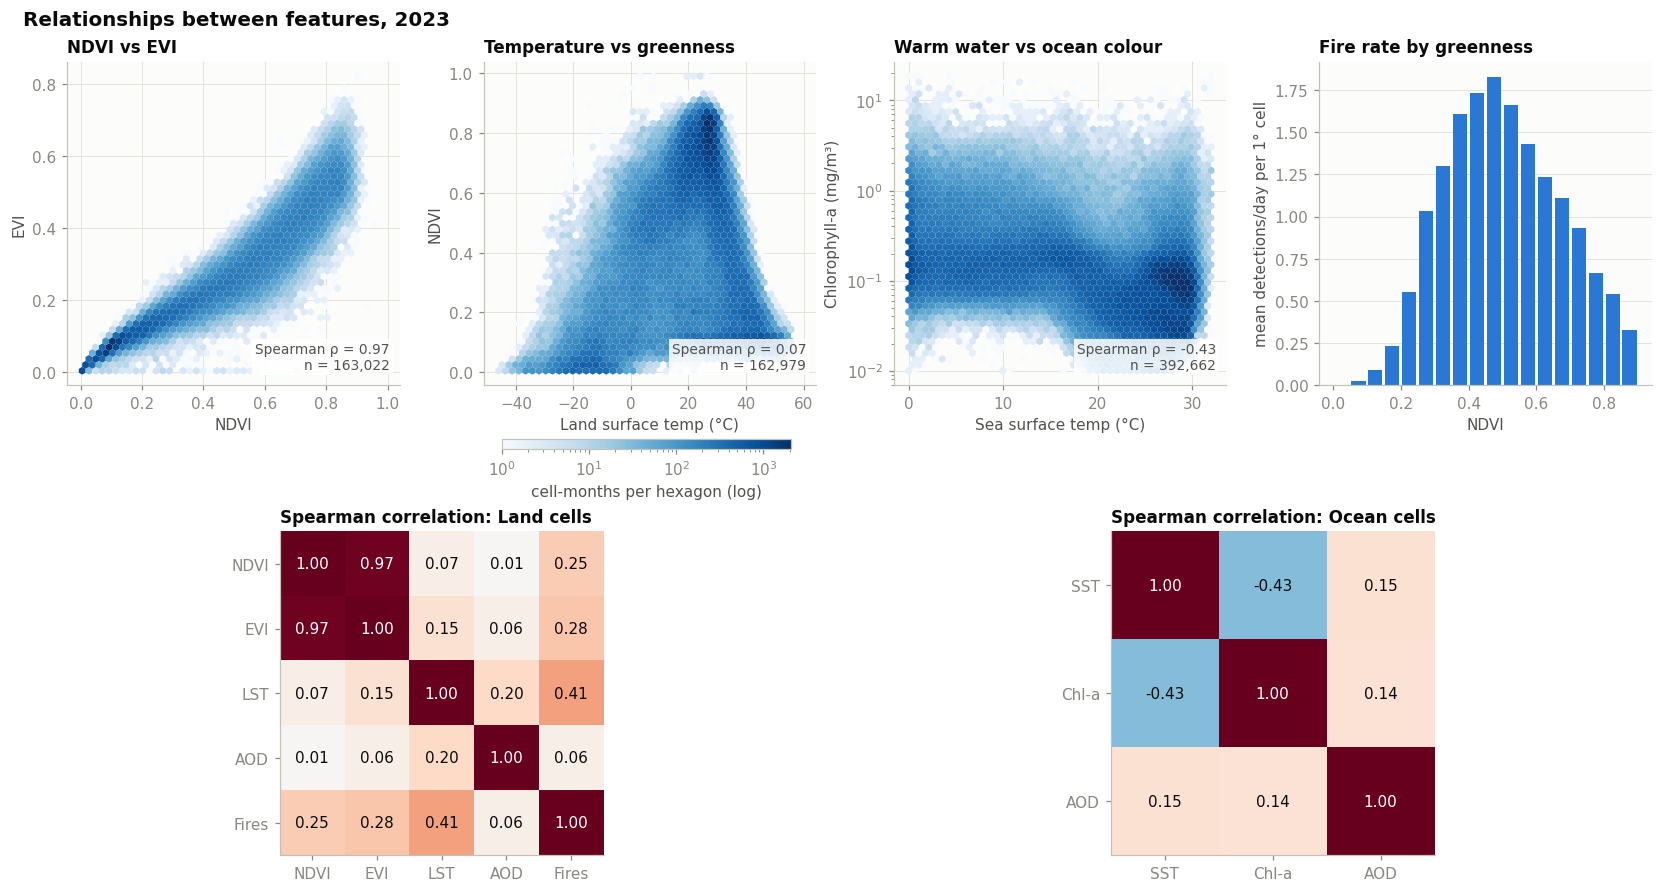

In [10]:
pairs = {k: coarsen(cubes[k], 2, "geomean" if FEATURES[k].get("log") else "mean").ravel() for k in FEATURES}
pairs["fire"] = coarsen(fire_rate, 2, "sum").ravel()
frame = pd.DataFrame(pairs)
is_land = np.tile(coarsen(land.astype("float32"), 2).ravel() > 0.5, 12)
land_frame = frame[is_land].drop(columns=["sst", "chl"])
ocean_frame = frame[~is_land][["sst", "chl", "aod"]]

fig = plt.figure(figsize=(15, 8), layout="constrained")
grid = fig.add_gridspec(2, 4)


def hex_panel(ax, x, y, xlabel, ylabel, title, yscale="linear"):
    keep = np.isfinite(x) & np.isfinite(y)
    if yscale == "log":
        keep &= y > 0
    hb = ax.hexbin(x[keep], y[keep], gridsize=45, cmap="Blues", bins="log", mincnt=1, yscale=yscale, linewidths=0)
    rho = pd.Series(x[keep]).corr(pd.Series(y[keep]), method="spearman")
    ax.set(xlabel=xlabel, ylabel=ylabel)
    ax.set_title(title, loc="left")
    ax.text(0.97, 0.05, f"Spearman ρ = {rho:.2f}\nn = {keep.sum():,}", transform=ax.transAxes, ha="right", color=INK2, fontsize=9,
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))
    return hb


hb = hex_panel(fig.add_subplot(grid[0, 0]), land_frame.ndvi.values, land_frame.evi.values, "NDVI", "EVI", "NDVI vs EVI")
hb = hex_panel(fig.add_subplot(grid[0, 1]), land_frame.lst.values, land_frame.ndvi.values, "Land surface temp (°C)", "NDVI", "Temperature vs greenness")
hb = hex_panel(fig.add_subplot(grid[0, 2]), ocean_frame.sst.values, ocean_frame.chl.values, "Sea surface temp (°C)", "Chlorophyll-a (mg/m³)", "Warm water vs ocean colour", "log")
fig.colorbar(hb, ax=fig.axes, location="bottom", shrink=0.25, label="cell-months per hexagon (log)", aspect=30, pad=0.02)

ax = fig.add_subplot(grid[0, 3])
bins = np.arange(0, 0.95, 0.05)
binned = land_frame.dropna(subset=["ndvi"]).groupby(pd.cut(land_frame.ndvi, bins), observed=True).fire.mean()
ax.bar([b.mid for b in binned.index], binned.values, width=0.042, color=SLOTS[0])
ax.set(xlabel="NDVI", ylabel="mean detections/day per 1° cell")
ax.set_title("Fire rate by greenness", loc="left")
ax.grid(axis="x", visible=False)

ax = fig.add_subplot(grid[1, 0:2])
labels = {"ndvi": "NDVI", "evi": "EVI", "lst": "LST", "aod": "AOD", "fire": "Fires", "sst": "SST", "chl": "Chl-a"}
land_corr = land_frame.corr("spearman")
ocean_corr = ocean_frame.corr("spearman")
for axis, corr, title in ((ax, land_corr, "Land cells"), (fig.add_subplot(grid[1, 2:4]), ocean_corr, "Ocean cells")):
    im = axis.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    names = [labels[c] for c in corr.columns]
    axis.set_xticks(range(len(names)), names)
    axis.set_yticks(range(len(names)), names)
    axis.grid(False)
    axis.set_title(f"Spearman correlation: {title}", loc="left")
    for r in range(len(names)):
        for c in range(len(names)):
            v = corr.iat[r, c]
            axis.text(c, r, f"{v:.2f}", ha="center", va="center", color="white" if abs(v) > 0.6 else INK, fontsize=10)
fig.suptitle("Relationships between features, 2023", x=0.01, ha="left", fontweight="bold", fontsize=13)
save(fig, "05_feature_relationships")

**What stands out**

- **NDVI and EVI are nearly redundant** (ρ = 0.97), but above NDVI 0.8 EVI keeps ranging from about 0.4 to 0.75 while NDVI barely moves. That fits NDVI saturating over dense vegetation, so EVI is the better choice for forests.
- **A near-zero correlation can hide strong structure.** Temperature vs NDVI has ρ = 0.07 but forms a clear triangle: greenness is highest near 25–30 °C and falls away at both extremes.
- **Warm water is mostly low in chlorophyll** (ρ = −0.43), which fits warm surface water being nutrient-poor.
- **Fires peak at intermediate greenness.** The rate near NDVI 0.45–0.5 (1.8 detections/day) is more than five times that at NDVI 0.85–0.9. One possible reading is that deserts lack fuel and wet forest burns less readily, but this analysis doesn't test that.
- **Fire vs aerosol is only ρ = 0.06 on land,** despite the map similarity. Smoke travels away from its source, and most cell-months have no fires, so a same-cell correlation is a weak test.

## 6. Inside the fire records

The vector tiles expose attributes that imagery can't, including fire radiative power (FRP),
brightness temperature, detection time and satellite.

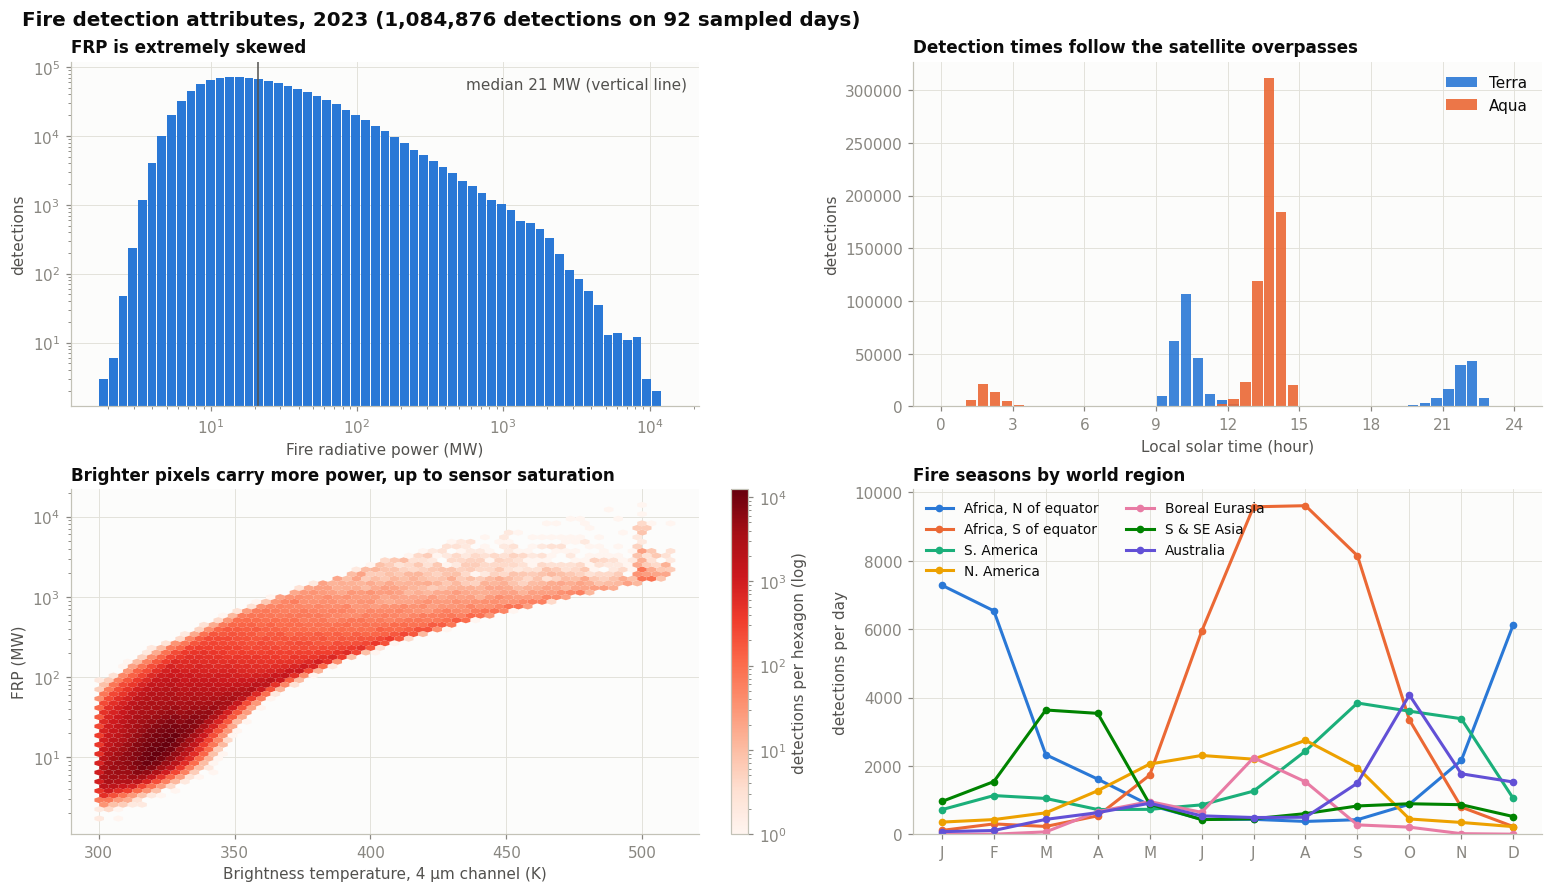

Median FRP 21.0 MW; top 1% of detections hold 20.6% of total FRP
             count   50%  mean
daynight                      
D         923234.0  21.8  51.1
N         161642.0  16.9  41.8
Boreal Canada detections/day by month: [13.0, 4.0, 2.0, 4.0, 1047.0, 1382.0, 1362.0, 1589.0, 1475.0, 34.0, 34.0, 8.0]


In [11]:
fire_zones = {
    "Africa, N of equator": (0, 40, -20, 55), "Africa, S of equator": (-40, 0, -20, 55),
    "S. America": (-60, 15, -85, -30), "N. America": (15, 75, -170, -50),
    "Boreal Eurasia": (50, 80, 30, 180), "S & SE Asia": (-10, 50, 60, 150),
    "Australia": (-45, -10, 110, 155),
}
zone = pd.Series("Other", index=good_fires.index)
for name, (s, n, w, e) in reversed(list(fire_zones.items())):
    zone[good_fires.latitude.between(s, n) & good_fires.longitude.between(w, e)] = name
monthly_zone = (good_fires.groupby([good_fires.acq_date.dt.month, zone]).size().unstack(fill_value=0)
                .div(days_per_month, axis=0))

local_hour = (good_fires.acq_time.str[:2].astype(int) + good_fires.acq_time.str[3:].astype(int) / 60
              + good_fires.longitude / 15) % 24

fig, axes = plt.subplots(2, 2, figsize=(14, 8), layout="constrained")
ax = axes[0, 0]
frp = good_fires.frp[good_fires.frp > 0]
ax.hist(frp, bins=np.logspace(np.log10(frp.min()), np.log10(frp.max()), 60), color=SLOTS[0], rwidth=0.9)
ax.set_xscale("log")
ax.set_yscale("log")
ax.axvline(frp.median(), color=INK2, lw=1)
ax.text(0.98, 0.92, f"median {frp.median():.0f} MW (vertical line)", transform=ax.transAxes, ha="right", color=INK2)
ax.set(xlabel="Fire radiative power (MW)", ylabel="detections")
ax.set_title("FRP is extremely skewed", loc="left")

ax = axes[0, 1]
for code, name, color in (("T", "Terra", SLOTS[0]), ("A", "Aqua", SLOTS[1])):
    ax.hist(local_hour[good_fires.satellite == code], bins=np.arange(0, 24.5, 0.5), rwidth=0.85, color=color, alpha=0.9, label=name)
ax.set_xticks(range(0, 25, 3))
ax.set(xlabel="Local solar time (hour)", ylabel="detections")
ax.set_title("Detection times follow the satellite overpasses", loc="left")
ax.legend(frameon=False)

ax = axes[1, 0]
sample = good_fires[good_fires.frp > 0]
hb = ax.hexbin(sample.brightness, sample.frp, gridsize=60, yscale="log", bins="log", cmap="Reds", mincnt=1, linewidths=0)
fig.colorbar(hb, ax=ax, label="detections per hexagon (log)")
ax.set(xlabel="Brightness temperature, 4 µm channel (K)", ylabel="FRP (MW)")
ax.set_title("Brighter pixels carry more power, up to sensor saturation", loc="left")

ax = axes[1, 1]
for (name, color) in zip(fire_zones, SLOTS):
    ax.plot(range(1, 13), monthly_zone[name], color=color, lw=2, marker="o", ms=4, label=name)
ax.set_xticks(range(1, 13), [n[0] for n in MONTH_NAMES])
ax.set_ylim(bottom=0)
ax.set(ylabel="detections per day")
ax.set_title("Fire seasons by world region", loc="left")
ax.legend(frameon=False, ncol=2, fontsize=9)
fig.suptitle(f"Fire detection attributes, 2023 ({len(good_fires):,} detections on {fires.acq_date.nunique()} sampled days)",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
save(fig, "06_fire_attributes")

print(f"Median FRP {frp.median():.1f} MW; top 1% of detections hold {frp[frp >= frp.quantile(.99)].sum() / frp.sum():.1%} of total FRP")
print(good_fires.groupby("daynight").frp.describe()[["count", "50%", "mean"]].round(1))
print("Boreal Canada detections/day by month:", regional("fire", "Boreal Canada").round(0).tolist())

**What stands out**

- **A few detections carry much of the power.** Median FRP is 21 MW, but the top 1% of detections hold 20.6% of total FRP.
- **The time-of-day chart reflects when satellites look,** not simply when fires burn. MODIS sees each location only around its overpasses. Aqua's early-afternoon pass records far more fires than Terra's morning pass, and only 15% of detections are at night.
- **Sensor saturation is visible.** The cluster near 500 K at the right of the brightness chart suggests the 4 µm channel's upper limit.
- **Each region has its own fire season:** Africa north of the equator peaks in January, South and Southeast Asia in March and April, Africa south of the equator in July and August, South America in September, and Australia in October.

## 7. Case study: combining layers on one day

In early June 2023, smoke from Quebec's fires drifted over the northeastern US. This view
overlays three layers for 6 June 2023. The composited monthly data above can't show this event.

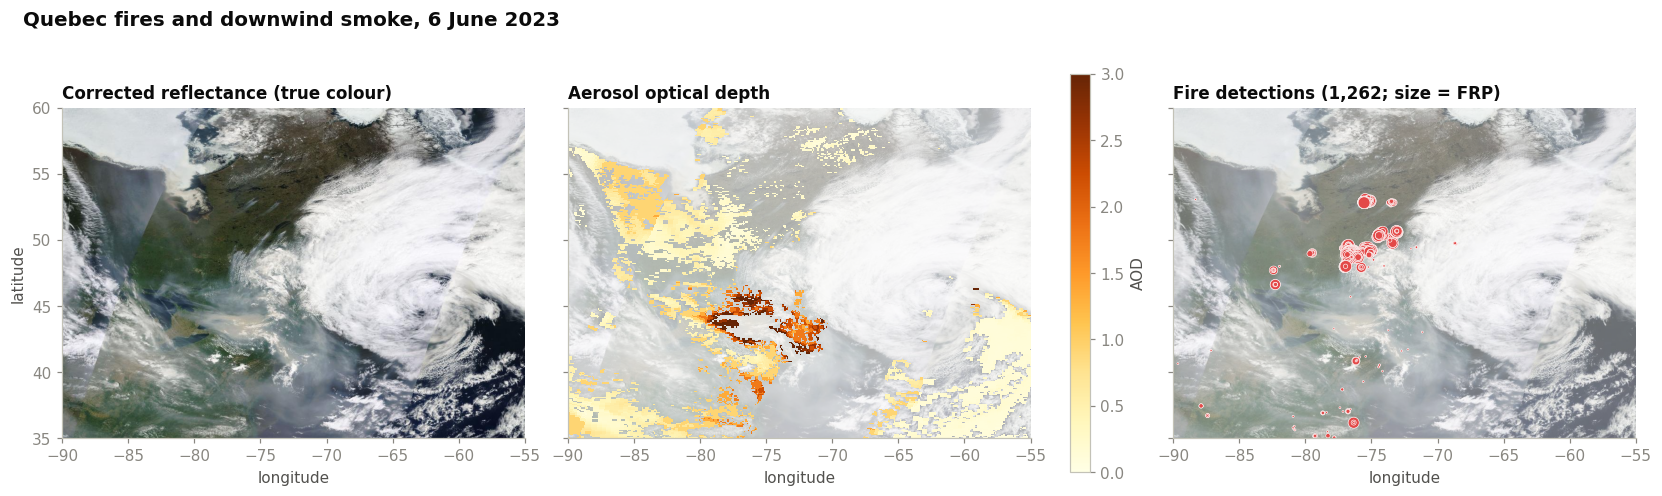

AOD p50/p99 in box: [0.46 3.49] | valid pixels: 18.5%
Fire detections in box: 1262 | total FRP (MW): 151550


In [12]:
CASE_DAY = "2023-06-06"
BBOX = (35, 60, -90, -55)
bbox_text = f"{BBOX[0]},{BBOX[2]},{BBOX[1]},{BBOX[3]}"
case_extent = [BBOX[2], BBOX[3], BBOX[0], BBOX[1]]
cw, ch = 980, 700
true_colour = get_image("MODIS_Terra_CorrectedReflectance_TrueColor", CASE_DAY, cw, ch, bbox_text, "image/jpeg")
aod_rgba = get_image(FEATURES["aod"]["layer"], CASE_DAY, cw, ch, bbox_text)
aod_case = decode(aod_rgba, *COLORMAP_CACHE[FEATURES["aod"]["colormap"]])
case_fires = good_fires[(good_fires.acq_date == CASE_DAY) & good_fires.latitude.between(BBOX[0], BBOX[1])
                        & good_fires.longitude.between(BBOX[2], BBOX[3])]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), layout="constrained", sharey=True)
axes[0].imshow(true_colour, extent=case_extent)
axes[0].set_title("Corrected reflectance (true colour)", loc="left")
axes[1].imshow(true_colour, extent=case_extent, alpha=0.35)
im = axes[1].imshow(aod_case, extent=case_extent, cmap="YlOrBr", vmin=0, vmax=3, interpolation="nearest")
fig.colorbar(im, ax=axes[1], label="AOD", shrink=0.85)
axes[1].set_title("Aerosol optical depth", loc="left")
axes[2].imshow(true_colour, extent=case_extent, alpha=0.6)
axes[2].scatter(case_fires.longitude, case_fires.latitude, s=np.clip(case_fires.frp, 8, 300) / 5,
                         c=SLOTS[7], edgecolors="white", linewidths=0.4)
axes[2].set_title(f"Fire detections ({len(case_fires):,}; size = FRP)", loc="left")
for ax in axes:
    ax.grid(False)
    ax.set_xlabel("longitude")
axes[0].set_ylabel("latitude")
fig.suptitle("Quebec fires and downwind smoke, 6 June 2023", x=0.01, ha="left", fontweight="bold", fontsize=13)
save(fig, "07_quebec_smoke_case")
print("AOD p50/p99 in box:", np.nanpercentile(aod_case, [50, 99]).round(2), "| valid pixels:", f"{np.isfinite(aod_case).mean():.1%}")
print("Fire detections in box:", len(case_fires), "| total FRP (MW):", round(case_fires.frp.sum()))

**What stands out**

- The fires cluster at 46–53°N, while the highest aerosol values appear several hundred kilometres south, around Ontario and New York. AOD reaches 3.5 at the 99th percentile, against a box median of 0.46.
- **Most of the box has no aerosol retrieval.** Only 18.5% of pixels are valid because of cloud. Gaps inside the plume may mean some of the thickest smoke was screened out, so these figures could understate the peak.

## 8. Two decades of change

Monthly grids from 2003 to 2025 on a 1° grid. Anomalies are each cell's departure from its own
2003–2025 average for that calendar month, which removes the seasonal cycle.
Chlorophyll, aerosol and fires are excluded because they would need thousands of daily requests.

In [13]:
LONG_KEYS = ["ndvi", "lst", "sst"]
LONG_FEATURES = {k: FEATURES[k] for k in LONG_KEYS}
LONG_FEATURES["lst_aqua"] = dict(FEATURES["lst"], layer="MODIS_Aqua_L3_Land_Surface_Temp_Monthly_Day")
LONG_MONTHS = pd.date_range("2003-01-01", "2025-12-01", freq="MS")
lat1 = 90 - (np.arange(180) + 0.5)
lon1 = -180 + (np.arange(360) + 0.5)


def fetch_long(key):
    path = DATA / f"{key}_2003_2025_1deg.npz"
    if path.exists():
        return np.load(path)["cube"]
    feature = LONG_FEATURES[key]
    with ThreadPoolExecutor(6) as pool:
        grids = list(pool.map(lambda d: read_grid(feature, d.strftime("%Y-%m-%d"), 360, 180), LONG_MONTHS))
    stack = np.stack(grids).astype("float32")
    np.savez_compressed(path, cube=stack)
    return stack


long_cubes = {k: fetch_long(k) for k in LONG_FEATURES}
month_index = LONG_MONTHS.month.to_numpy()


def anomalies(cube):
    out = np.full_like(cube, np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        for m in range(1, 13):
            selected = month_index == m
            out[selected] = cube[selected] - np.nanmean(cube[selected], axis=0)
    return out


long_anom = {k: anomalies(c) for k, c in long_cubes.items()}
GLOBE = (-90, 90, -180, 180)
NINO34 = REGIONS["Niño 3.4 (Pacific)"]
series = pd.DataFrame({
    "Global land NDVI": area_mean(long_anom["ndvi"], GLOBE, lat1, lon1),
    "Global land surface temp, Terra daytime (°C)": area_mean(long_anom["lst"], GLOBE, lat1, lon1),
    "Global sea surface temp (°C)": area_mean(long_anom["sst"], GLOBE, lat1, lon1),
    "Niño 3.4 sea surface temp (°C)": area_mean(long_anom["sst"], NINO34, lat1, lon1),
}, index=LONG_MONTHS)
months_with_data = {k: int(np.isfinite(c).any(axis=(1, 2)).sum()) for k, c in long_cubes.items()}
print("Months with data out of", len(LONG_MONTHS), ":", months_with_data)
nino = series["Niño 3.4 sea surface temp (°C)"]
print("Niño 3.4 warmest:", {d.strftime("%Y-%m"): round(v, 2) for d, v in nino.nlargest(4).items()})
print("Niño 3.4 coolest:", {d.strftime("%Y-%m"): round(v, 2) for d, v in nino.nsmallest(4).items()})
print("Annual anomalies:\n", series.groupby(series.index.year).mean().round(3).iloc[[0, 5, 10, 15, 20, 21, 22]])

Months with data out of 276 : {'ndvi': 275, 'lst': 276, 'sst': 271, 'lst_aqua': 276}
Niño 3.4 warmest: {'2015-11': 2.83, '2015-12': 2.62, '2016-01': 2.55, '2015-10': 2.49}
Niño 3.4 coolest: {'2010-12': -1.8, '2007-11': -1.73, '2008-02': -1.72, '2007-12': -1.68}
Annual anomalies:
       Global land NDVI  Global land surface temp, Terra daytime (°C)  \
2003            -0.010                                         0.018   
2008            -0.009                                        -0.112   
2013            -0.002                                         0.205   
2018            -0.001                                         0.178   
2023             0.008                                        -0.081   
2024             0.012                                        -0.785   
2025             0.014                                        -1.875   

      Global sea surface temp (°C)  Niño 3.4 sea surface temp (°C)  
2003                        -0.140                           0.263  
2008

### Interactive: anomaly time series

Each measure has its own panel and axis. Hover for values and drag across a panel to zoom.
The standalone page is `figures/08_longterm_anomalies.html`.

In [14]:
trends = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.035, subplot_titles=list(series.columns))
for i, column in enumerate(series.columns, start=1):
    trends.add_trace(go.Scatter(x=series.index, y=series[column], mode="lines", name=column,
                                line=dict(color=SLOTS[0], width=1.6), showlegend=False,
                                hovertemplate="%{x|%b %Y}: %{y:+.3f}<extra></extra>"), row=i, col=1)
    trends.add_hline(y=0, line=dict(color="#c3c2b7", width=1), row=i, col=1)
trends.update_layout(height=760, width=1100, template="simple_white", hovermode="x",
                     title=dict(text="Monthly anomalies vs each cell's 2003–2025 average", x=0.01),
                     font=dict(family="system-ui, Segoe UI, sans-serif", color=INK2),
                     margin=dict(t=70, b=40, l=60, r=20))
trends.update_yaxes(gridcolor=GRID, showgrid=True, zeroline=False)
trends.update_xaxes(showgrid=False, showspikes=True, spikemode="across", spikecolor=MUTED, spikethickness=1)
show_plotly(trends, "08_longterm_anomalies")

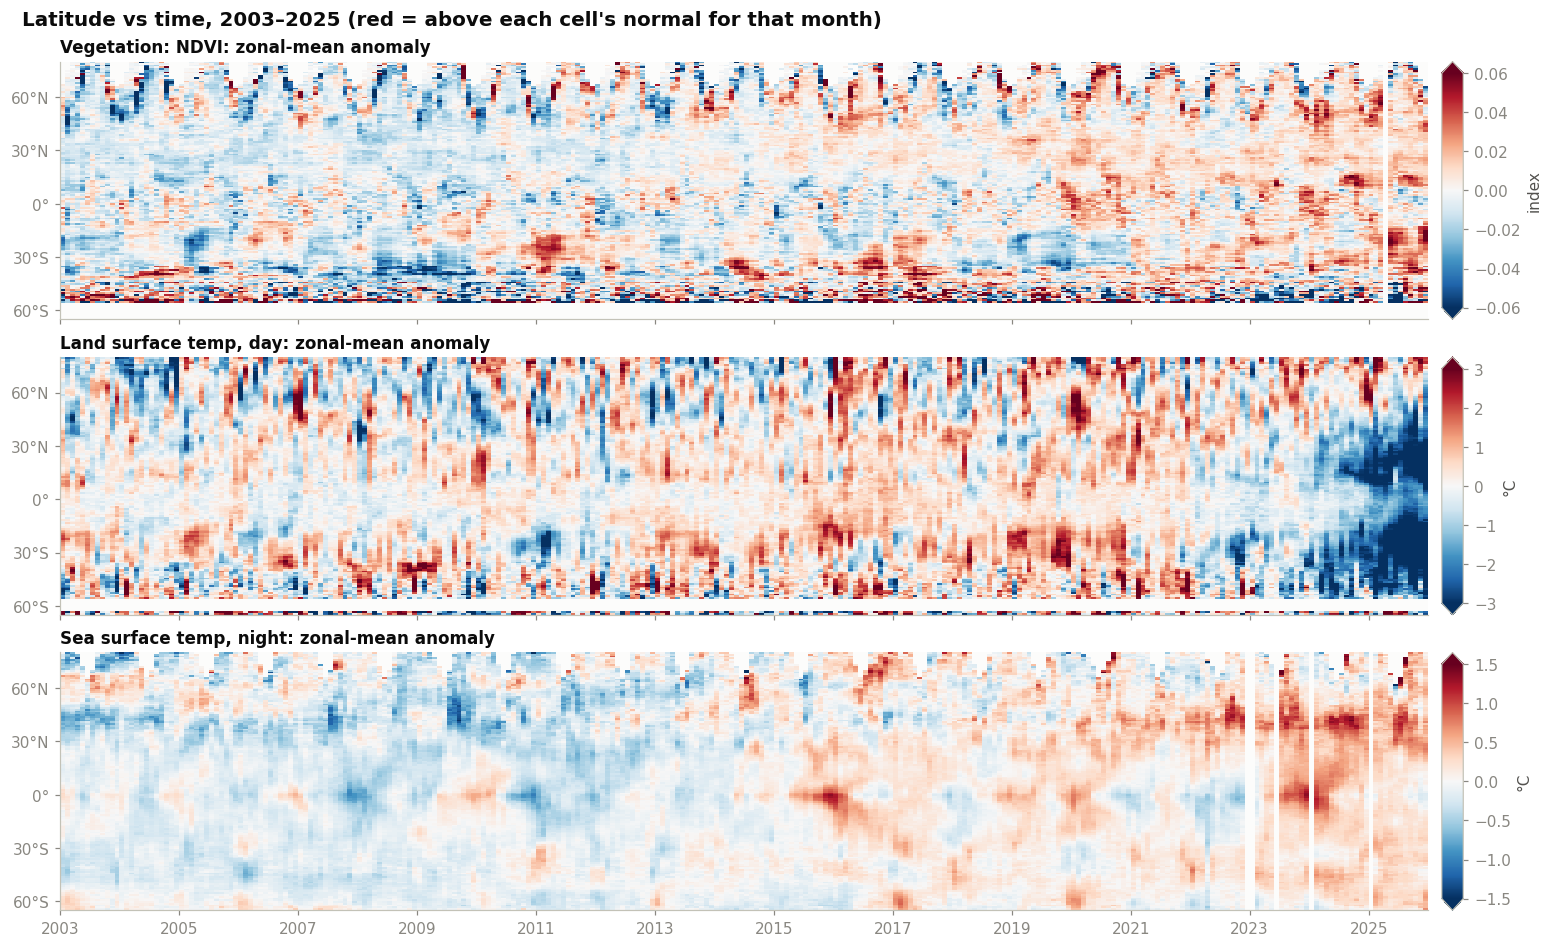

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8.5), layout="constrained", sharex=True)
LONG_LIMITS = dict(ndvi=0.06, lst=3, sst=1.5)
for ax, key in zip(axes, LONG_KEYS):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        z = np.nanmean(long_anom[key], axis=2).T
    im = ax.imshow(z, aspect="auto", extent=[0, len(LONG_MONTHS), -90, 90], cmap="RdBu_r",
                   norm=TwoSlopeNorm(0, -LONG_LIMITS[key], LONG_LIMITS[key]), interpolation="nearest")
    fig.colorbar(im, ax=ax, label=FEATURES[key]["units"], extend="both", aspect=12, pad=0.01)
    ax.set_title(f"{FEATURES[key]['title']}: zonal-mean anomaly", loc="left")
    ax.set_ylim(-65, 80)
    ax.set_yticks([-60, -30, 0, 30, 60], ["60°S", "30°S", "0°", "30°N", "60°N"])
    ax.set_xticks(np.arange(0, len(LONG_MONTHS), 24), LONG_MONTHS[::24].year)
    ax.grid(False)
fig.suptitle("Latitude vs time, 2003–2025 (red = above each cell's normal for that month)",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
save(fig, "09_latitude_time_anomalies")

**What stands out**

- **El Niño and La Niña events line up with known history,** which is also a good test of the colour-to-value pipeline: +2.8 °C in November 2015, +2.0 °C in December 2023 and −1.8 °C in December 2010.
- **Global SST warms** from −0.14 °C in 2003 to +0.40 °C in 2024, relative to the 2003–2025 average.
- **Global land NDVI rises** from −0.010 to +0.014 across the record. Part of this could be instrument or orbit related, which hasn't been tested here.
- **The land temperature panel collapses after about 2022,** spreading out from the low latitudes. The next section tests whether that's real.

### Is the recent land "cooling" real?

The Terra panel above shows land cooling sharply after about 2022, spreading out from the
tropics. Before believing it, compare two independent tests: a second satellite (Aqua), and
each satellite's actual overpass time, measured from the timestamps on its daytime fire
detections (one mid-July day per year).

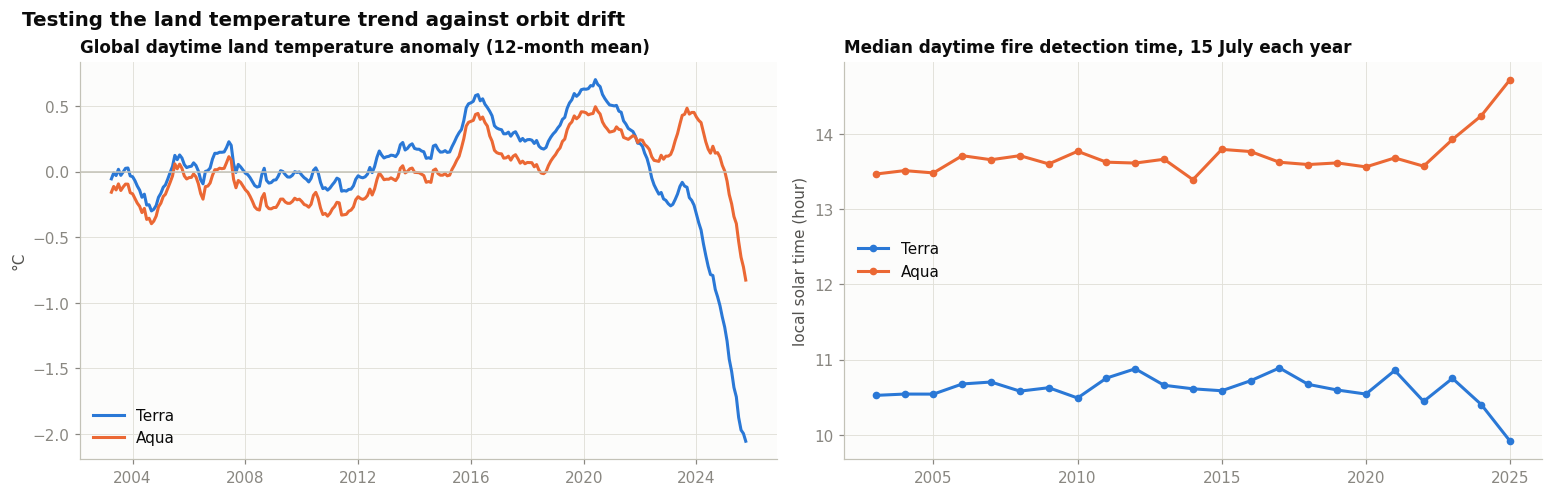

 year     A     T
 2003 13.47 10.52
 2013 13.66 10.66
 2020 13.56 10.54
 2021 13.68 10.86
 2022 13.57 10.44
 2023 13.93 10.75
 2024 14.24 10.40
 2025 14.72  9.92
      Terra  Aqua
2010   0.03 -0.16
2015   0.27  0.09
2019   0.52  0.36
2020   0.67  0.46
2021   0.36  0.25
2022  -0.10  0.09
2023  -0.08  0.43
2024  -0.78  0.14
2025  -1.87 -0.53
Niño 3.4 peak in 2023-24: 2023-12 2.02
Sahara AOD coverage by month: [1.0, 1.0, 0.99, 0.98, 0.99, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In [16]:
def overpass_table():
    path = DATA / "overpass_july15.csv"
    if path.exists():
        return pd.read_csv(path)
    years = range(2003, 2026)
    with ThreadPoolExecutor(6) as pool:
        days = list(pool.map(lambda y: fire_day(f"{y}-07-15"), years))
    rows = []
    for year, day in zip(years, days):
        hour = day.ACQ_TIME.str[:2].astype(int) + day.ACQ_TIME.str[3:].astype(int) / 60
        day = day.assign(local=(hour + day.LONGITUDE / 15) % 24)
        daytime = day[day.DAYNIGHT == "D"]
        # Older records label satellites "Terra"/"Aqua" and newer ones "T"/"A".
        rows.append(dict(year=year, **daytime.groupby(daytime.SATELLITE.str[0]).local.median().to_dict()))
    table = pd.DataFrame(rows)
    table.to_csv(path, index=False)
    return table


overpass = overpass_table()
lst_series = pd.DataFrame({
    "Terra": area_mean(long_anom["lst"], GLOBE, lat1, lon1),
    "Aqua": area_mean(long_anom["lst_aqua"], GLOBE, lat1, lon1),
}, index=LONG_MONTHS)
smooth = lst_series.rolling(12, center=True, min_periods=9).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), layout="constrained")
ax = axes[0]
for name, color in (("Terra", SLOTS[0]), ("Aqua", SLOTS[1])):
    ax.plot(smooth.index, smooth[name], color=color, lw=2, label=name)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set(ylabel="°C")
ax.set_title("Global daytime land temperature anomaly (12-month mean)", loc="left")
ax.legend(frameon=False, loc="lower left")

ax = axes[1]
for code, name, color in (("T", "Terra", SLOTS[0]), ("A", "Aqua", SLOTS[1])):
    ax.plot(overpass.year, overpass[code], color=color, lw=2, marker="o", ms=4, label=name)
ax.set(ylabel="local solar time (hour)")
ax.set_title("Median daytime fire detection time, 15 July each year", loc="left")
ax.legend(frameon=False, loc="center left")
fig.suptitle("Testing the land temperature trend against orbit drift", x=0.01, ha="left", fontweight="bold", fontsize=13)
save(fig, "10_lst_drift_check")

print(overpass.iloc[[0, 10, 17, 18, 19, 20, 21, 22]].round(2).to_string(index=False))
print(lst_series.groupby(lst_series.index.year).mean().round(2).loc[[2010, 2015, 2019, 2020, 2021, 2022, 2023, 2024, 2025]])
print("Niño 3.4 peak in 2023-24:", nino["2023":"2024"].idxmax().strftime("%Y-%m"), round(nino["2023":"2024"].max(), 2))
print("Sahara AOD coverage by month:", np.isfinite(cubes["aod"][(slice(None), *box_mask(REGIONS["Sahara"]))]).mean(axis=(1, 2)).round(2).tolist())

**Verdict: mainly an artifact.**

- **The overpass time moved.** Terra's median daytime detection shifts from about 10.5 h to 9.9 h local time between 2003 and 2025, and Aqua's from about 13.5 h to 14.7 h. These are single-day medians, so year-to-year wobble of a few tenths of an hour is noise, but the post-2022 shift stands out.
- **The two satellites disagree when they drift.** Terra's anomaly goes from +0.67 °C in 2020 to −1.87 °C in 2025. Aqua's stays positive through 2024 (+0.14 °C) and reaches only −0.53 °C in 2025. Land heats quickly through the morning, so an earlier Terra overpass should read much cooler, and a later Aqua pass near the daily peak should change less.
- **Aqua's own 2025 drop is also suspect,** because its overpass has moved furthest by then.

This comparison shows the pattern fits drift, but it doesn't measure how much is drift. No correction is applied here, so use Terra LST trends only through about 2021. The 2023 maps above are still useful for spatial and seasonal patterns, though Terra reads about 0.5 °C lower than Aqua's anomaly that year.

## 9. Limitations

- **Values are recovered from colours,** so they're rounded to colormap bins, and anything beyond the published scale is clipped (LST at 200–350 K, AOD at 5, chlorophyll at 20 mg/m³). The science-grade files from NASA Earthdata are the better source for precise work.
- **Grids are samples.** Returned pixels match the colormap exactly, which implies GIBS isn't blending them, so a 0.5° pixel is probably one sampled value and not an area average.
- **Chlorophyll, aerosol and fires are sampled every 4th day** (92 days in 2023). Fire counts are detections per sampled day and not annual totals, and one detection isn't one fire.
- **Fire records aren't all wildfires.** Agricultural burning, gas flares and volcanoes aren't removed. Detections are limited by cloud and overpass timing, and the 2023 records are labelled near-real-time (`6.1NRT`).
- **Cloud, snow and darkness remove data unevenly,** which biases composites toward clear conditions. Chlorophyll in coastal and inland water is unreliable, with values around 15 mg/m³ over some Canadian lakes.
- **The feature set has gaps.** In the long-term SST series, 2022-12, 2023-01, 2023-06, 2024-01 and 2025-01 are missing, and NDVI lacks 2025-04. They're left as gaps.
- **Relationships are descriptive.** They pool space and season across a single year, and anomalies use a 2003–2025 baseline that includes the drift years.